# Занятие 6. Линейная регрессия

**Задача регрессии:** по признакам объекта предсказать число — например, время поездки по расстоянию и числу остановок.

Для обучения нужны примеры с известными ответами. По ним мы подбираем параметры модели, а затем применяем её к новым объектам.

**Цель:** собрать первую ML-модель из знакомых частей: векторов и матриц, MSE и градиентного спуска.

У нас будет одна линейная модель и одна задача — уменьшить MSE. Рассмотрим два подхода: градиентный спуск и прямое решение задачи наименьших квадратов (least squares). Реализуем их на NumPy, затем сравним с готовым `sklearn.LinearRegression`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("dark_background")
plt.rcParams["figure.facecolor"] = "#0b1020"
plt.rcParams["axes.facecolor"] = "#111827"
plt.rcParams["savefig.facecolor"] = "#0b1020"
plt.rcParams["axes.edgecolor"] = "#64748b"
plt.rcParams["grid.color"] = "#334155"

np.set_printoptions(precision=3, suppress=True)


## 1. Линейная модель

Для одного объекта с признаками $x_1,\ldots,x_m$:

$$
\widehat{y} = x^\top w + b.
$$

Здесь:

- $x$ — признаки объекта;
- $w$ — веса признаков;
- $b$ — свободный член;
- $\widehat{y}$ — предсказание модели.

Если объектов сразу много, складываем их по строкам матрицы $X$:

$$
\widehat{\mathbf{y}} = Xw + b.
$$

Проверка по формам: если `X.shape == (n, m)` и `w.shape == (m,)`, то предсказаний должно получиться `n`.

Перед запуском следующей ячейки посчитайте мысленно: чему равно предсказание при `x = [4, 1]`, `w = [3, 2]` и `b = 5`?

In [2]:
# Один объект
x = np.array([4.0, 1.0])
w = np.array([3.0, 2.0])
b = 5.0

print("one object:", x @ w + b)

# Сразу три объекта
X_small = np.array([
    [4.0, 1.0],
    [2.0, 5.0],
    [0.0, 3.0],
])

pred_small = X_small @ w + b

print("X_small.shape =", X_small.shape)
print("w.shape       =", w.shape)
print("predictions   =", pred_small)
print("pred shape    =", pred_small.shape)

one object: 19.0
X_small.shape = (3, 2)
w.shape       = (2,)
predictions   = [19. 21. 11.]
pred shape    = (3,)


## 2. Как понять, хороши ли предсказания?

Для каждого объекта есть остаток (ошибка предсказания):

$$
e_i = \widehat{y}_i - y_i.
$$

Чтобы получить одно число для всей модели, возводим остатки в квадрат и усредняем:

$$
\mathrm{MSE}
=
\frac{1}{n}
\sum_{i=1}^{n}
(\widehat{y}_i-y_i)^2.
$$

Чем меньше MSE, тем ближе предсказания к правильным ответам.


Для геометрической иллюстрации возьмём один признак. При одном и том же $x$ сравниваем высоту точки и прямой. Длина отрезка равна $|e_i|$, а знак $e_i = \widehat{y}_i - y_i$ показывает, завышено или занижено предсказание.

![Вертикальные отрезки показывают модуль ошибки](attachment:residuals_dark.png)

In [3]:
# Предсказания именно той модели, которую только что посчитали
y_pred = pred_small
y_true = np.array([18.0, 25.0, 10.0])

error = y_pred - y_true
squared_error = error ** 2

print("ошибки         =", error)
print("квадраты ошибок =", squared_error)
print("MSE             =", squared_error.mean())

ошибки         = [ 1. -4.  1.]
квадраты ошибок = [ 1. 16.  1.]
MSE             = 6.0


In [4]:
def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

mse(y_true, y_pred)

np.float64(6.0)

## 3. Данные для обучения

Сделаем синтетический датасет с двумя признаками: линейная зависимость плюс случайный шум. Шум изображает разброс ответов, который наши признаки не объясняют.

Истинные параметры известны нам только как авторам генератора. **При обучении `X` и `y` фиксированы; меняются только `w` и `b`.** Алгоритм не получает `true_w` и `true_b` — они нужны для проверки результата.

In [5]:
rng = np.random.default_rng(7)
n = 80

X = np.column_stack([
    rng.uniform(0, 10, n),
    rng.uniform(0, 10, n),
])

true_w = np.array([3.0, 4.0])
true_b = 20.0
noise = rng.normal(0, 2.5, n)

y = X @ true_w + true_b + noise

print("X.shape =", X.shape)
print("y.shape =", y.shape)
print("first 3 objects:")
print(X[:3])
print("first 3 targets:", y[:3])

X.shape = (80, 2)
y.shape = (80,)
first 3 objects:
[[6.251 1.925]
 [8.972 9.279]
 [7.757 5.523]]
first 3 targets: [50.587 82.355 62.728]


## 4. Градиент MSE

Для текущих параметров ошибки равны $e = Xw + b - y$.

Для одного веса $w_j$:

$$
\frac{\partial \mathrm{MSE}}{\partial w_j}
= \frac{2}{n}\sum_{i=1}^{n}e_i x_{ij}.
$$

Умножаем ошибку каждого объекта на его признак $x_{ij}$ и складываем. Матричное умножение считает эти суммы сразу для всех весов:

$$
\nabla_w \mathrm{MSE} = \frac{2}{n}X^\top e.
$$

Сдвиг $b$ входит в каждое предсказание с множителем 1, поэтому:

$$
\frac{\partial \mathrm{MSE}}{\partial b}
= \frac{2}{n}\sum_{i=1}^{n}e_i = 2\,\mathrm{mean}(e).
$$

Градиент показывает направление роста ошибки. Для её уменьшения делаем небольшой шаг **против** градиента.

Один шаг обучения:

$$
w \leftarrow w - \eta \nabla_w \mathrm{MSE},
$$

$$
b \leftarrow b - \eta \frac{\partial \mathrm{MSE}}{\partial b}.
$$

$\eta$ — `learning_rate`, то есть размер шага.

Слишком большой `learning_rate` может привести к росту ошибки. Здесь шаг подобран для наших данных; это не универсальное значение.

### Как выглядит градиентный спуск

Для анимации возьмём отдельный датасет с **одним признаком** и модель $\widehat{y} = wx + b$.

Три графика показывают один и тот же шаг обучения:

- **Слева сверху:** прямая с текущими $w$ и $b$ на фиксированных данных.
- **Слева снизу:** MSE в зависимости от числа шагов обучения.
- **Справа:** поверхность MSE для разных пар $(w, b)$. Шарик отмечает текущие параметры; его высота — текущая MSE. След показывает уже пройденный путь.

Поверхность не меняется: на каждом шаге мы выбираем другую пару параметров. «Скатывание» изображает шаги против градиента; инерцию шарика мы не моделируем.

![Прямая, MSE по шагам и движение по поверхности ошибки](attachment:gd_line_animation.gif)


Числа MSE в этой анимации относятся только к её данным; их не сравниваем с MSE основного примера ниже.

In [6]:
w_gd = np.zeros(X.shape[1])
b_gd = 0.0

learning_rate = 0.01
steps = 3000
losses = []

for step in range(steps):
    # 1. Предсказания
    y_pred = X @ w_gd + b_gd

    # 2. Ошибка и MSE до текущего обновления
    error = y_pred - y
    losses.append(mse(y, y_pred))

    # 3. Оба градиента для текущих параметров
    grad_w = (2 / len(X)) * (X.T @ error)
    grad_b = 2 * error.mean()

    # 4. Шаг против градиента
    w_gd -= learning_rate * grad_w
    b_gd -= learning_rate * grad_b

# Последняя точка — ошибка после всех обновлений
final_mse = mse(y, X @ w_gd + b_gd)
losses.append(final_mse)
print("MSE до обучения:", round(losses[0], 3))
print("MSE после обучения:", round(final_mse, 3))

MSE до обучения: 3268.431
MSE после обучения: 5.476


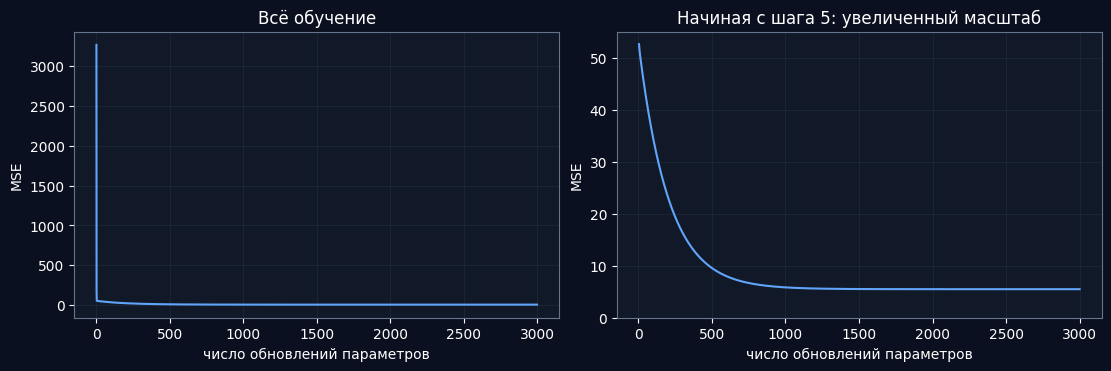

In [7]:
# Готовая ячейка визуализации: в эфире достаточно её запустить
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
axes[0].plot(np.arange(len(losses)), losses, color="#60a5fa")
axes[0].set_title("Всё обучение")

zoom_start = 5
axes[1].plot(np.arange(zoom_start, len(losses)), losses[zoom_start:], color="#60a5fa")
axes[1].set_title("Начиная с шага 5: увеличенный масштаб")
axes[1].set_ylim(bottom=0)

for ax in axes:
    ax.set_xlabel("число обновлений параметров")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.3)
plt.show()

In [8]:
print("true w =", true_w, "   learned by GD =", w_gd)
print("true b =", true_b, "        learned by GD =", round(b_gd, 3))

true w = [3. 4.]    learned by GD = [2.92  3.951]
true b = 20.0         learned by GD = 20.458


Из-за случайного шума параметры, лучше всего подходящие этой выборке, немного отличаются от параметров генератора. Даже хорошо обученная модель не обязана иметь нулевую MSE.

Остаётся вопрос: насколько близко градиентный спуск подошёл к минимуму? Для линейной регрессии это можно проверить прямым решением.

## 5. Аналитическое решение least squares

MSE линейной модели — квадратичная функция параметров. Её минимум можно найти, решив линейную систему.

### Сначала включим сдвиг в общий вектор параметров

Добавим к каждому объекту признак, всегда равный 1:

```text
признаки:     [x1, x2, 1]
параметры:    [w1, w2, b]
предсказание: x1*w1 + x2*w2 + 1*b
```

В матричной записи:

$$
\widetilde{X} = [X\;\mathbf{1}],
\qquad \theta = \begin{bmatrix}w\\b\end{bmatrix},
\qquad \widehat{y} = \widetilde{X}\theta.
$$

In [ ]:
# Последний столбец — единицы, последний параметр — свободный член b
X_aug = np.column_stack([X, np.ones(len(X))])
print("X_aug.shape =", X_aug.shape)
print(X_aug[:3])

X_aug.shape = (80, 3)
[[6.251 1.925 1.   ]
 [8.972 9.279 1.   ]
 [7.757 5.523 1.   ]]


### Приравняем градиент к нулю

Минимизируем сумму квадратов ошибок:

$$
\sum_{i=1}^{n}(\widetilde{x}_i^\top\theta-y_i)^2.
$$

Множитель $1/n$ из MSE не меняет положение минимума, поэтому его можно опустить.
Нулевой градиент даёт **нормальные уравнения**:

$$
\widetilde{X}^{\top}\widetilde{X}\theta = \widetilde{X}^{\top}y.
$$

Если столбцы $\widetilde{X}$ линейно независимы, матрица слева обратима и решение единственно:

$$
\theta = (\widetilde{X}^{\top}\widetilde{X})^{-1}\widetilde{X}^{\top}y.
$$

В коде явное вычисление обратной матрицы — лишняя работа, которая также может добавлять численные погрешности. Систему решают через `solve`. Однако само формирование $\widetilde{X}^{\top}\widetilde{X}$ может усиливать численные проблемы.

**Практический выбор — `lstsq`:** решает least squares непосредственно по `X_aug` и `y`, в том числе когда минимум достигается при нескольких наборах параметров.

In [ ]:
# Для этих данных нормальные уравнения имеют единственное решение
theta_normal = np.linalg.solve(X_aug.T @ X_aug, X_aug.T @ y)

# Основной практический вариант: первый результат lstsq — параметры
theta_lstsq = np.linalg.lstsq(X_aug, y, rcond=None)[0]
w_analytic = theta_lstsq[:-1]
b_analytic = theta_lstsq[-1]

print("solve:", theta_normal)
print("lstsq:", theta_lstsq)

solve: [ 2.919  3.95  20.47 ]
lstsq: [ 2.919  3.95  20.47 ]


### Что, если два признака одинаковые?

Если $x_2=x_1$, то

$$
\widehat y = w_1x_1+w_2x_1+b=(w_1+w_2)x_1+b.
$$

Предсказания зависят только от суммы весов. Отдельные $w_1$ и $w_2$ по таким данным нельзя определить однозначно.

In [ ]:
# Отдельный пример: два одинаковых признака, свободный член равен 0
x_dup = np.array([1.0, 2.0, 3.0])
X_dup = np.column_stack([x_dup, x_dup])

for weights in [np.array([2., 3.]), np.array([4., 1.]), np.array([100., -95.])]:
    print("веса:", weights, "→ предсказания:", X_dup @ weights)

веса: [2. 3.] → предсказания: [ 5. 10. 15.]
веса: [4. 1.] → предсказания: [ 5. 10. 15.]
веса: [100. -95.] → предсказания: [ 5. 10. 15.]


Это пример **коллинеарности признаков**: один столбец выражается через другой. Точная линейная зависимость столбцов делает $X^\top X$ необратимой. Формула с inverse неприменима; `lstsq` может выбрать одно из решений, но однозначность отдельных весов не возвращает.

Если признаки **почти** линейно зависимы, небольшие изменения данных могут сильно менять веса. При этом предсказания на похожих объектах могут оставаться близкими. Надёжность коэффициентов и качество предсказаний — разные вопросы.

### Ridge: штраф за большие веса

Один из способов сделать решение устойчивее — добавить к ошибке штраф за величину весов:

$$
L(w,b)=\mathrm{MSE}(w,b)+\lambda\sum_j w_j^2,\qquad\lambda>0.
$$

При одинаковых предсказаниях предпочитаем меньшую сумму квадратов весов. Модель может также немного изменить предсказания, чтобы уменьшить штраф. Это **L2-регуляризация**, или **Ridge**.

**Обучающая MSE может стать больше:** теперь минимизируем ошибку вместе со штрафом. Цель — получить более устойчивое решение; улучшение качества на новых данных нужно проверять. Свободный член $b$ в этой формуле не штрафуется.

## 6. То же самое через `sklearn`

`LinearRegression` обучает ту же линейную модель, решая задачу наименьших квадратов. Для нашей плотной матрицы используется специализированный least-squares решатель, а не написанный выше градиентный спуск.

`fit(X, y)` подбирает параметры. По умолчанию библиотека сама учитывает свободный член: передаём исходный `X`, без добавленного столбца единиц.

In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)

sk_pred = model.predict(X)

In [11]:
# Готовый вывод для сравнения — все MSE на одной обучающей выборке
print(f"{'метод':<12} {'w1':>8} {'w2':>8} {'b':>8} {'MSE train':>12}")
for name, weights, bias in [
    ("GD", w_gd, b_gd),
    ("lstsq", w_analytic, b_analytic),
    ("sklearn", model.coef_, model.intercept_),
]:
    loss = mse(y, X @ weights + bias)
    print(f"{name:<12} {weights[0]:8.3f} {weights[1]:8.3f} {bias:8.3f} {loss:12.6f}")

метод              w1       w2        b    MSE train


NameError: name 'w_analytic' is not defined

## 7. Предсказания на новых объектах

Параметры уже найдены. `predict` применяет линейную функцию; веса при этом не меняются.

В `predict` передаём двумерный массив: строки — объекты, столбцы — те же признаки в том же порядке, что при обучении. Для одного объекта: `model.predict([[2.0, 7.0]])`.

In [12]:
X_new = np.array([
    [2.0, 7.0],
    [8.0, 1.0],
])

manual_pred = X_new @ model.coef_ + model.intercept_
sklearn_pred = model.predict(X_new)

print("manual: ", manual_pred)
print("sklearn:", sklearn_pred)

manual:  [53.959 47.771]
sklearn: [53.959 47.771]


## 8. Как модель работает на данных, которых не видела?

До сих пор MSE считалась на обучающих объектах (**train**). Теперь проверим модель на отдельной выборке (**test**) с известными ответами. Эти ответы используются только для оценки.

Для учебного примера создадим test по тому же рецепту, но с новыми случайными признаками и шумом. В реальной задаче часть данных заранее откладывают для проверки.

In [13]:
# Готовим отдельные данные для проверки, не меняя обученную модель
rng_test = np.random.default_rng(17)
X_test = rng_test.uniform(0, 10, size=(40, 2))
y_test = X_test @ true_w + true_b + rng_test.normal(0, 2.5, len(X_test))

In [14]:
test_pred = model.predict(X_test)  # здесь только predict, без fit

# Простой ориентир: всегда выдавать средний ответ обучающей выборки
baseline_pred = np.full(len(X_test), y.mean())

print("MSE модели на train:", round(mse(y, sk_pred), 3))
print("MSE модели на test: ", round(mse(y_test, test_pred), 3))
print("MSE среднего на test:", round(mse(y_test, baseline_pred), 3))

MSE модели на train: 5.476
MSE модели на test:  6.067
MSE среднего на test: 165.911


На новых данных модель ошибается заметно меньше, чем постоянный прогноз средним значением. Здесь она смогла использовать зависимость между признаками и ответом.

Train и test MSE могут различаться: это разные объекты и разный шум. Ошибка на train сама по себе ещё не показывает качество на новых данных.

## 9. Может ли линейная регрессия описать кривую?

Да, если преобразовать исходные признаки. Например, для $x\geq0$ возьмём новый признак $z=\sqrt{x}$:

$$
\widehat y=wz+b=w\sqrt{x}+b.
$$

В координатах $(x,y)$ это кривая, но по обучаемым параметрам $w$ и $b$ модель остаётся линейной. Признак $z$ вычисляется из известного $x$ ещё до обучения.

Сравним на отдельном учебном датасете модели с признаком $x$ и с признаком $\sqrt{x}$.

In [ ]:
# Готовые данные для отдельной демонстрации
rng_curve = np.random.default_rng(23)
x_curve = np.linspace(0, 16, 45)
y_curve = 2 + 3 * np.sqrt(x_curve) + rng_curve.normal(0, 0.3, len(x_curve))

# Каждый объект теперь имеет один признак; форма матрицы — (45, 1)
X_raw = x_curve.reshape(-1, 1)
X_sqrt = np.sqrt(x_curve).reshape(-1, 1)

In [ ]:
line_model = LinearRegression().fit(X_raw, y_curve)
sqrt_model = LinearRegression().fit(X_sqrt, y_curve)

print("Train MSE, признак x:      ", round(mse(y_curve, line_model.predict(X_raw)), 3))
print("Train MSE, признак sqrt(x):", round(mse(y_curve, sqrt_model.predict(X_sqrt)), 3))

Train MSE, признак x:       0.548
Train MSE, признак sqrt(x): 0.104


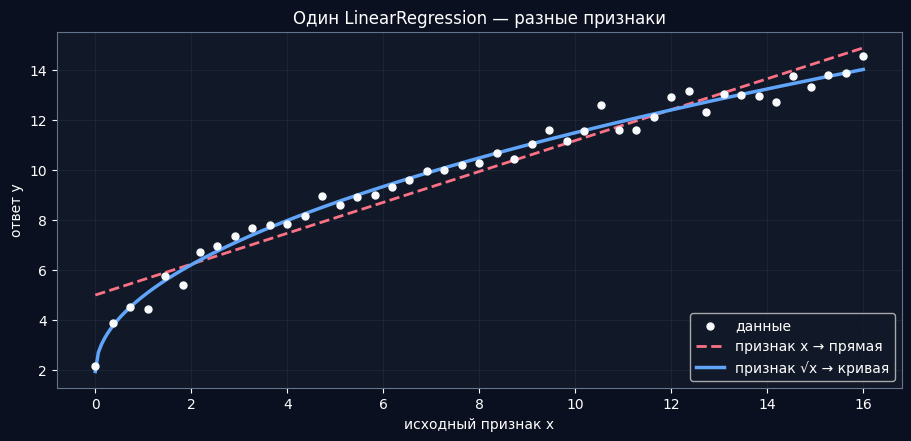

In [ ]:
# Готовая визуализация: на новых x применяем то же преобразование признака
x_grid = np.linspace(0, 16, 250)
fig, ax = plt.subplots(figsize=(9, 4.3), layout="constrained")
ax.scatter(x_curve, y_curve, color="#f8fafc", s=25, label="данные", zorder=3)
ax.plot(x_grid, line_model.predict(x_grid.reshape(-1, 1)),
        color="#fb7185", linestyle="--", linewidth=2, label="признак x → прямая")
ax.plot(x_grid, sqrt_model.predict(np.sqrt(x_grid).reshape(-1, 1)),
        color="#60a5fa", linewidth=2.5, label="признак √x → кривая")
ax.set(xlabel="исходный признак x", ylabel="ответ y",
       title="Один LinearRegression — разные признаки")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.show()

При предсказании преобразуем новые объекты **так же, как обучающие**. Признак `sqrt(x)` подходит только для неотрицательных `x`.

Такое создание признаков называют **feature engineering**. Удачный признак позволяет линейной модели описать нелинейную зависимость. Способ обучения при этом не меняется.

## 10. Проверка понимания

Модель уже обучена. Пришёл один новый объект с признаками `[2.0, 7.0]`.

1. Что вызываем: `fit` или `predict`?
2. Меняются ли `w` и `b`?
3. Можно ли посчитать MSE, если правильный ответ для этого объекта ещё неизвестен?

Сначала ответьте мысленно, затем откройте разбор.

<details>
<summary>Разбор</summary>

Вызываем `model.predict([[2.0, 7.0]])`. Веса и сдвиг не меняются: применяем уже обученную модель. Для MSE нужен правильный ответ, поэтому одного предсказания недостаточно.

</details>

---

## Что унести с занятия

1. Линейная модель предсказывает число: $\widehat{y}=Xw+b$. Обучение подбирает параметры по известным ответам.
2. GD и прямой least-squares решатель минимизируют одну MSE; `LinearRegression` предоставляет готовое решение.
3. `fit` обучает, `predict` применяет модель. Качество проверяем на данных, не участвовавших в обучении.
4. Зависимые признаки могут делать веса неоднозначными или неустойчивыми. Ridge добавляет штраф за большие веса.
5. Линейность по весам не мешает описывать кривые: можно преобразовать исходные признаки.